# 1. Final Pipeline: Candidate Generation → Reranker

Runs the final two-stage system on validation and evaluates it end to end:

- **Candidate generation** (fixed, from `5_01`): 500 candidates per impression. Ranks
  1–200 are the popularity top 200; ranks 201–500 are the content model's top 300, with
  articles already retrieved by popularity replaced by further popularity candidates.
- **Reranker**: the final `RR_4` model (`+metadata`, softmax + LambdaNDCG, full training
  set), which orders those 500 candidates.

The budget comparison that led to this setting is in `PE_two_stage_pipeline.ipynb`.

**Labels are incomplete.** A retrieved article that was never shown has unknown relevance:
it counts as "not a known click", not as a negative. Every known click stays in the
denominator, so clicks the generator missed count as misses. `candidate_recall` (the share
of known clicks retrieved at all) caps every ranking metric. Section 5 therefore also
reports the **shown-only** metrics, which measure ranking quality where relevance is known.

## 1.1 Load Packages

In [1]:
import json
import sys
import time
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import polars as pl
import pyarrow as pa
import pyarrow.parquet as pq
import torch
from IPython.display import display
from torch import nn

KeyboardInterrupt: 

## 1.2 Set Up Paths

Set `ENVIRONMENT` to `"colab"` to read the project and data from Google Drive. The
repository supplies the shared evaluator and the feature-engineering package; the data
folder holds the prepared features and receives every score file and metric table.

In [ ]:
ENVIRONMENT = "local"  # "local" or "colab"

if ENVIRONMENT == "colab":
    from google.colab import drive
    drive.mount("/content/drive")
    PROJECT_ROOT = Path("/content/drive/MyDrive/BT4222-Group-6-")
    DATA_ROOT = Path("/content/drive/MyDrive/v3-mindsmall")
else:
    PROJECT_ROOT = Path("/Users/numkoos/Downloads/BT4222-Group-6-")
    DATA_ROOT = Path("/Users/numkoos/Downloads/v3-mindsmall")

# Ranking features, click labels and causal user histories from feature engineering
RUN = DATA_ROOT / "4_Feature_Engineering" / "artifacts" / "prequential-all"

# Frozen article embeddings from the representation stage
REPRESENTATIONS = DATA_ROOT / "3_Representations" / "artifacts"

# Checkpoints, score files and metric tables written by the reranking notebooks
ARTIFACTS = DATA_ROOT / "5_Models" / "5_02_Reranking" / "artifacts"
RESULTS = DATA_ROOT / "results"

# Processed request/event tables used by the causal feature replay
PROCESSED_ROOT = DATA_ROOT / "processed"

# Final candidate generation output: per impression, ranks 1-200 popularity, 201-500 content
CANDIDATES = Path("/Users/numkoos/Downloads/recommendations_validation_top500.parquet")

# Optional: the two-retriever file (ranks 1-500 popularity, 501-1250 content), used only to
# label which retriever produced each candidate. None falls back to the rank layout above.
#SOURCE_CANDIDATES = Path("/Users/numkoos/Downloads/recommendations_validation_top1250.parquet")

# Shared evaluator, and the feature-engineering package used to replay causal features
sys.path.insert(0, str(PROJECT_ROOT / "5_Models" / "5_02_Reranking"))
sys.path.insert(0, str(PROJECT_ROOT / "src"))
from rr_evaluation import evaluate_retrieved_candidates
from newsrec.common import DEFAULT_SETTINGS
from newsrec.pipeline import replay_batches, time_horizon
from newsrec.ranking import TemporalState, build_features, feature_schema
from newsrec.representations import Bundle

## 1.3 Load Generated Candidates

One row per (impression, candidate), with `cutoff` giving the candidate's rank in the
generator output.

In [ ]:
candidate_summary = (
    pl.scan_parquet(CANDIDATES)
    .select(
        pl.len().alias("rows"),
        pl.col("impression_uid").n_unique().alias("impressions"),
        pl.col("cutoff").min().alias("first_rank"),
        pl.col("cutoff").max().alias("last_rank"),
    )
    .collect()
)
display(candidate_summary)
pl.scan_parquet(CANDIDATES).head(5).collect()

rows,impressions,first_rank,last_rank
u32,u32,i16,i16
15812000,31624,1,500


impression_uid,cutoff,news_code
i64,i16,i32
10154218,1,7821
10154218,2,42977
10154218,3,12029
10154218,4,52723
10154218,5,33885


# 2. Experiment Configuration

Scoring is the expensive step: causal features are built for every (impression,
candidate) pair during a replay of the timeline. `EVAL_IMPRESSIONS` scores a fixed random
subset of impressions (the same seed and subset as `PE_two_stage_pipeline.ipynb`); `None`
scores all 31,624 (about 15.8M pairs).

The reranker scores each candidate independently, and no ranking feature depends on the
rest of the candidate list. So any pair already scored by `PE_two_stage_pipeline.ipynb`
with the same reranker has exactly the same score here; `REUSE_SCORES` picks those up and
only the remaining pairs are replayed.

In [ ]:
SEED = 4222
DEVICE = "cuda" if torch.cuda.is_available() else "mps" if torch.backends.mps.is_available() else "cpu"
print(f"Using {DEVICE}")

# Reranker to load (an RR_4_branch_interaction output folder)
RERANKER_DIR = ARTIFACTS / "branch_interaction"
RERANKER_NAME = "branch_plus_metadata__softmax_plus_lambda_ndcg__full_data"

EVAL_IMPRESSIONS = 10_000        # None = every impression in the candidate file
POPULARITY_TOP = 200             # fallback source labels: ranks 1..200 are popularity
QUOTAS = (10, 8, 5)              # popularity slots in the top 10 for the quota merge
TOP_K = 10                       # length of the final recommendation list

# Must match the settings the reranker was trained with in RR_4
MODEL_DIM = 64
ATTENTION_HEADS = 2
ATTENTION_DROPOUT = 0.10
HIDDEN_DIMS = (256, 64)
DROPOUT = 0.20
HISTORY_CAP = 30
SHORT_TERM_CAP = 10
SCORING_BATCH_ROWS = 4096

OUTPUT_DIR = DATA_ROOT / "5_Models" / "5_03_Pipeline_Evaluation" / "artifacts"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
impression_tag = "all" if EVAL_IMPRESSIONS is None else f"{EVAL_IMPRESSIONS}imp"
SCORE_PATH = OUTPUT_DIR / f"{RERANKER_NAME}__final_top500_{impression_tag}.parquet"

# Scores from PE_two_stage_pipeline.ipynb for the same reranker (None = always replay)
REUSE_SCORES = OUTPUT_DIR / f"{RERANKER_NAME}__pop500_content750_{impression_tag}.parquet"
print(f"Score file: {SCORE_PATH}")

Using mps
Score file: /Users/numkoos/Downloads/v3-mindsmall/5_Models/5_03_Pipeline_Evaluation/artifacts/branch_plus_metadata__softmax_plus_lambda_ndcg__full_data__final_top500_10000imp.parquet


# 3. Load the Reranker

## 3.1 Article Inputs

The same article tables the reranker was trained with, indexed by `article_row`.

In [ ]:
article_index = pl.read_parquet(
    REPRESENTATIONS / "article_index.parquet",
    columns=["news_code", "article_row", "category_code", "subcategory_code"],
)
news_to_row = dict(zip(article_index["news_code"].to_list(), article_index["article_row"].to_list()))

text_vectors = np.load(REPRESENTATIONS / "text64.npy", mmap_mode="r")
entity_vectors = np.load(REPRESENTATIONS / "article_entity100.npy", mmap_mode="r")
title_tokens = np.load(REPRESENTATIONS / "title_token_ids.npy").astype(np.int64)
N_ARTICLES = text_vectors.shape[0]

# Category and subcategory codes per article row (0 = padding / unknown)
article_category = np.zeros(N_ARTICLES, dtype=np.int64)
article_subcategory = np.zeros(N_ARTICLES, dtype=np.int64)
article_category[article_index["article_row"].to_numpy()] = article_index["category_code"].to_numpy()
article_subcategory[article_index["article_row"].to_numpy()] = article_index["subcategory_code"].to_numpy()
print(f"{N_ARTICLES:,} article rows; {article_category.max()} categories; "
      f"{article_subcategory.max()} subcategories; title vocabulary {title_tokens.max() + 1:,}")

51,283 article rows; 17 categories; 257 subcategories; title vocabulary 28,714


## 3.2 Model Components

These cells are copied unchanged from `RR_4_branch_interaction.ipynb`, so the saved
weights load directly. See that notebook for the explanation of each component.

In [ ]:
class AdditiveAttention(nn.Module):
    """Pool a sequence of history states into one user vector with learned relevance weights."""

    def __init__(self, dim):
        super().__init__()
        self.proj = nn.Linear(dim, dim)
        self.query = nn.Parameter(torch.randn(dim) * 0.02)

    def forward(self, states, padding_mask):
        # states: [batch, history, dim]; padding_mask: [batch, history], True = padding
        all_padded = padding_mask.all(dim=1)
        safe_mask = padding_mask.clone()
        safe_mask[all_padded, 0] = False                       # softmax needs one open slot

        scores = torch.tanh(self.proj(states)) @ self.query    # [batch, history]
        weights = torch.softmax(scores.masked_fill(safe_mask, -1e9), dim=1)
        weights = weights.masked_fill(padding_mask, 0.0)
        weights = weights / weights.sum(dim=1, keepdim=True).clamp(min=1e-8)
        return (weights.unsqueeze(-1) * states).sum(dim=1)     # [batch, dim]

In [ ]:
class NewsEncoder(nn.Module):
    """Map article rows to MODEL_DIM news vectors from the enabled article inputs."""

    def __init__(self, config):
        super().__init__()
        self.config = config
        self.register_buffer("text", torch.from_numpy(np.array(text_vectors, dtype=np.float32)), persistent=False)
        width = self.text.shape[1]

        if config["metadata"]:
            self.register_buffer("entity", torch.from_numpy(np.array(entity_vectors, dtype=np.float32)), persistent=False)
            self.register_buffer("category", torch.from_numpy(article_category), persistent=False)
            self.register_buffer("subcategory", torch.from_numpy(article_subcategory), persistent=False)
            self.category_embedding = nn.Embedding(int(article_category.max()) + 1, 16, padding_idx=0)
            self.subcategory_embedding = nn.Embedding(int(article_subcategory.max()) + 1, 16, padding_idx=0)
            self.entity_projection = nn.Linear(self.entity.shape[1], 32)
            width += 16 + 16 + 32

        if config["title_encoder"]:
            self.register_buffer("title_tokens", torch.from_numpy(title_tokens), persistent=False)
            self.word_embedding = nn.Embedding(int(title_tokens.max()) + 1, MODEL_DIM, padding_idx=0)
            self.word_attention = nn.MultiheadAttention(MODEL_DIM, ATTENTION_HEADS, dropout=ATTENTION_DROPOUT, batch_first=True)
            self.word_pool = AdditiveAttention(MODEL_DIM)
            width += MODEL_DIM

        self.output = nn.Sequential(nn.Linear(width, MODEL_DIM), nn.LayerNorm(MODEL_DIM))

    def encode_titles(self, rows):
        tokens = self.title_tokens[rows]                       # [articles, title_len]
        padding = tokens.eq(0)
        padding[padding.all(dim=1), 0] = False                 # padding articles keep one slot
        words = self.word_embedding(tokens)
        attended, _ = self.word_attention(words, words, words, key_padding_mask=padding, need_weights=False)
        return self.word_pool(attended, padding)

    def forward(self, rows):
        # Encode each distinct article in the batch once, then scatter back to every position
        unique_rows, inverse = torch.unique(rows, return_inverse=True)
        parts = [self.text[unique_rows]]
        if self.config["metadata"]:
            parts += [
                self.category_embedding(self.category[unique_rows]),
                self.subcategory_embedding(self.subcategory[unique_rows]),
                self.entity_projection(self.entity[unique_rows]),
            ]
        if self.config["title_encoder"]:
            parts.append(self.encode_titles(unique_rows))
        return self.output(torch.cat(parts, dim=-1))[inverse]   # rows.shape + [MODEL_DIM]

In [ ]:
class UserEncoder(nn.Module):
    """Encode the click history into per-candidate user vectors."""

    def __init__(self, config):
        super().__init__()
        self.config = config
        if config["position"]:
            self.position_embedding = nn.Embedding(HISTORY_CAP, MODEL_DIM)
        self.self_attention = nn.MultiheadAttention(MODEL_DIM, ATTENTION_HEADS, dropout=ATTENTION_DROPOUT, batch_first=True)
        self.norm1 = nn.LayerNorm(MODEL_DIM)
        self.feed_forward = nn.Sequential(
            nn.Linear(MODEL_DIM, 4 * MODEL_DIM),
            nn.ReLU(),
            nn.Dropout(ATTENTION_DROPOUT),
            nn.Linear(4 * MODEL_DIM, MODEL_DIM),
        )
        self.norm2 = nn.LayerNorm(MODEL_DIM)
        self.pool = AdditiveAttention(MODEL_DIM)
        self.default_user = nn.Parameter(torch.zeros(MODEL_DIM))
        if config["short_term"]:
            self.short_term = nn.GRU(MODEL_DIM, MODEL_DIM, batch_first=True)
            self.gate = nn.Linear(2 * MODEL_DIM, MODEL_DIM)
        self.last_gate = None

    @property
    def output_dim(self):
        return MODEL_DIM * (2 if self.config["candidate_pooling"] else 1)

    def forward(self, history, padding_mask, candidates):
        # history: [B, H, D]; padding_mask: [B, H] (True = padding); candidates: [B, W, D]
        empty = padding_mask.all(dim=1)
        safe_mask = padding_mask.clone()
        safe_mask[empty, -1] = False

        if self.config["position"]:
            # Column j of a left-padded history has recency rank H-1-j (0 = newest)
            ranks = torch.arange(HISTORY_CAP - 1, -1, -1, device=history.device)
            history = history + self.position_embedding(ranks)

        attended, _ = self.self_attention(history, history, history, key_padding_mask=safe_mask, need_weights=False)
        states = self.norm1(history + attended)
        states = self.norm2(states + self.feed_forward(states))
        states = states.masked_fill(padding_mask.unsqueeze(-1), 0.0)

        user = self.pool(states, padding_mask)
        if self.config["short_term"]:
            recent = states[:, -SHORT_TERM_CAP:]                       # newest clicks, zeros for padding
            _, short = self.short_term(recent)
            short = short.squeeze(0)
            gate = torch.sigmoid(self.gate(torch.cat([user, short], dim=1)))
            user = gate * user + (1 - gate) * short
            self.last_gate = gate.detach().mean().item()
        user = torch.where(empty.unsqueeze(1), self.default_user.unsqueeze(0), user)
        user = user.unsqueeze(1).expand(-1, candidates.shape[1], -1)   # [B, W, D]

        if not self.config["candidate_pooling"]:
            return user
        # Candidate-as-query attention over the contextualised history
        scores = candidates @ states.transpose(1, 2) / np.sqrt(MODEL_DIM)       # [B, W, H]
        scores = scores.masked_fill(safe_mask.unsqueeze(1), -1e9)
        weights = torch.softmax(scores, dim=-1).masked_fill(padding_mask.unsqueeze(1), 0.0)
        candidate_user = weights @ states                                       # [B, W, D]
        return torch.cat([user, candidate_user], dim=-1)

In [ ]:
class BranchReranker(nn.Module):
    """Score candidates from the enabled tabular, news and user branches."""

    def __init__(self, config, tabular_width):
        super().__init__()
        if config["user_encoder"] and not config["text"]:
            raise ValueError("The user encoder needs the news encoder (text=True)")
        if not (config["tabular"] or config["text"]):
            raise ValueError("At least one of the tabular or text branches must be on")
        self.config = config
        width = tabular_width if config["tabular"] else 0
        if config["text"]:
            self.news_encoder = NewsEncoder(config)
            width += MODEL_DIM
        if config["user_encoder"]:
            self.user_encoder = UserEncoder(config)
            width += self.user_encoder.output_dim

        layers = []
        for hidden in HIDDEN_DIMS:
            layers.extend([nn.Linear(width, hidden), nn.ReLU(), nn.Dropout(DROPOUT)])
            width = hidden
        layers.append(nn.Linear(width, 1))
        self.scorer = nn.Sequential(*layers)

    def forward(self, tabular, candidate_rows, history_rows):
        # tabular: [B, W, T]; candidate_rows: [B, W]; history_rows: [B, H] → logits [B, W]
        parts = [tabular] if self.config["tabular"] else []
        if self.config["text"]:
            candidates = self.news_encoder(candidate_rows)
            parts.append(candidates)
            if self.config["user_encoder"]:
                history = self.news_encoder(history_rows)
                parts.append(self.user_encoder(history, history_rows.eq(0), candidates))
        return self.scorer(torch.cat(parts, dim=-1)).squeeze(-1)

In [ ]:
def encode_histories(impression_ids, profiles):
    """Left-padded [impressions, HISTORY_CAP] article rows with the newest click last."""
    histories = np.zeros((len(impression_ids), HISTORY_CAP), dtype=np.int64)
    for index, uid in enumerate(impression_ids):
        history = profiles[uid][-HISTORY_CAP:]
        if len(history):
            histories[index, -len(history):] = history
    return histories

## 3.3 Load Weights and Preprocessing

The tabular preprocessor was fitted in `RR_4` on training data only. The feature schema
check guarantees the replayed features match what the model was trained on.

In [ ]:
checkpoint = torch.load(RERANKER_DIR / RERANKER_NAME / "model.pt", map_location=DEVICE, weights_only=False)
model = BranchReranker(checkpoint["config"], checkpoint["tabular_width"]).to(DEVICE)
model.load_state_dict(checkpoint["state_dict"])
model.eval()
preprocessor = joblib.load(RERANKER_DIR / "preprocessor.joblib")

FEATURES = json.loads((RUN / "feature_schema.json").read_text())["model_columns"]
if feature_schema(DEFAULT_SETTINGS)["model_columns"] != FEATURES:
    raise ValueError("The feature code and the saved feature run disagree on the schema")
print(f"Loaded {RERANKER_NAME}: branches {[name for name, on in checkpoint['config'].items() if on]}, "
      f"loss {checkpoint['loss']}")

Loaded branch_plus_metadata__softmax_plus_lambda_ndcg__full_data: branches ['tabular', 'text', 'metadata', 'user_encoder'], loss softmax+lambda_ndcg


# 4. Score the Candidates

The timeline is replayed in timestamp order. Each selected impression's candidates get
features from the state **before** that impression, and candidates never update the
state. Rows are scored in chunks and written to a partial file. Pairs found in
`REUSE_SCORES` are not replayed. An existing `SCORE_PATH` is reused as is.

In [ ]:
def select_candidates():
    """Candidates for the evaluated impressions (same random subset as the budget notebook)."""
    candidates = pl.scan_parquet(CANDIDATES)
    if EVAL_IMPRESSIONS is not None:
        ids = candidates.select("impression_uid").unique().sort("impression_uid").collect()["impression_uid"].to_numpy()
        chosen = np.random.default_rng(SEED).choice(ids, size=min(EVAL_IMPRESSIONS, len(ids)), replace=False)
        candidates = candidates.filter(pl.col("impression_uid").is_in(chosen.tolist()))
    return candidates.with_columns(pl.col("news_code").cast(pl.Int64)).collect()


def score_rows(frame, histories):
    """Reranker probabilities for feature rows (pointwise, in fixed-size chunks)."""
    uids = frame["impression_uid"].drop_duplicates().tolist()
    history_rows = encode_histories(uids, histories)
    history_index = frame["impression_uid"].map(pd.Series(np.arange(len(uids)), index=uids)).to_numpy()
    tabular = preprocessor.transform(frame[FEATURES]).astype(np.float32, copy=False)
    candidates = frame["news_code"].map(news_to_row).to_numpy(np.int64)

    scores = []
    with torch.no_grad():
        for start in range(0, len(frame), SCORING_BATCH_ROWS):
            stop = start + SCORING_BATCH_ROWS
            logits = model(
                torch.from_numpy(tabular[start:stop]).unsqueeze(1).to(DEVICE),
                torch.from_numpy(candidates[start:stop]).unsqueeze(1).to(DEVICE),
                torch.from_numpy(history_rows[history_index[start:stop]]).to(DEVICE),
            )
            scores.append(torch.sigmoid(logits.squeeze(1)).cpu().numpy())
    return np.concatenate(scores)


def score_generated_candidates(candidates, output_path):
    """Replay validation, build causal features for the given candidates and score them."""
    rows_by_impression = candidates.groupby("impression_uid", sort=False).indices
    print(f"Scoring {len(candidates):,} candidates for {len(rows_by_impression):,} impressions")

    profiles = pl.read_parquet(RUN / "request_profiles_validation" / "*.parquet",
                               columns=["impression_uid", "full_history_rows"])
    histories = dict(zip(profiles["impression_uid"].to_list(), profiles["full_history_rows"].to_list()))

    bundle = Bundle(DATA_ROOT, DEFAULT_SETTINGS)
    state = TemporalState(bundle, *time_horizon(PROCESSED_ROOT), DEFAULT_SETTINGS)
    partial_path = output_path.with_suffix(".partial.parquet")
    writer, pending, impressions, started = None, [], 0, time.monotonic()

    def flush():
        nonlocal writer, pending
        if not pending:
            return
        frame = pd.concat(pending, ignore_index=True)
        pending = []
        frame["score"] = score_rows(frame, histories)
        table = pa.Table.from_pandas(frame[["impression_uid", "news_code", "cutoff", "score"]], preserve_index=False)
        if writer is None:
            writer = pq.ParquetWriter(partial_path, table.schema, compression="zstd")
        writer.write_table(table)

    try:
        for timestamp, requests, events in replay_batches(PROCESSED_ROOT, DEFAULT_SETTINGS, splits=("train", "validation")):
            state.begin(requests, timestamp)
            selected = requests[requests["split"].eq("validation") & requests["impression_uid"].isin(set(rows_by_impression))]
            if len(selected):
                pairs = candidates.iloc[np.concatenate([rows_by_impression[uid] for uid in selected["impression_uid"]])]
                features = build_features(selected, pairs, state, bundle, DEFAULT_SETTINGS, "retrieved")
                pending.append(features.merge(pairs, on=["impression_uid", "news_code"], validate="one_to_one"))
                impressions += len(selected)
                if sum(len(frame) for frame in pending) >= 50_000:
                    flush()
                    print(f"  {impressions:,}/{len(rows_by_impression):,} impressions scored "
                          f"({(time.monotonic() - started) / 60:.1f} min)", flush=True)
            state.finish(requests, events, timestamp, {"train", "validation"})
        flush()
    finally:
        if writer is not None:
            writer.close()
        state.close()

    if impressions != len(rows_by_impression):
        raise ValueError(f"Scored {impressions:,} impressions but {len(rows_by_impression):,} were selected")
    partial_path.rename(output_path)
    print(f"Done in {(time.monotonic() - started) / 60:.1f} minutes")



def score_final_candidates():
    """Reuse matching pairs from REUSE_SCORES, replay the rest, and save one score file."""
    candidates = select_candidates()
    keys = ["impression_uid", "news_code"]
    reused = pl.DataFrame(schema={"impression_uid": pl.Int64, "news_code": pl.Int64, "score": pl.Float32})
    if REUSE_SCORES is not None and REUSE_SCORES.exists():
        cached = pl.scan_parquet(REUSE_SCORES).select(
            pl.col("impression_uid").cast(pl.Int64), pl.col("news_code").cast(pl.Int64), pl.col("score").cast(pl.Float32)
        )
        reused = candidates.lazy().select(keys).join(cached, on=keys, how="inner").collect()
    missing = candidates.join(reused, on=keys, how="anti")
    print(f"{candidates.height:,} candidates: {reused.height:,} reused, {missing.height:,} to score")

    parts = [reused]
    if missing.height:
        missing_path = SCORE_PATH.with_name(SCORE_PATH.stem + "__missing.parquet")
        if not missing_path.exists():
            score_generated_candidates(
                missing.to_pandas().sort_values(["impression_uid", "cutoff"]).reset_index(drop=True), missing_path
            )
        parts.append(pl.read_parquet(missing_path).select(
            pl.col("impression_uid").cast(pl.Int64), pl.col("news_code").cast(pl.Int64), pl.col("score").cast(pl.Float32)
        ))

    scored = candidates.join(pl.concat(parts), on=keys, how="left")
    if scored["score"].null_count() or scored.height != candidates.height:
        raise ValueError("Some candidates have no score")
    scored.write_parquet(SCORE_PATH)


if not SCORE_PATH.exists():
    score_final_candidates()
scores = pl.read_parquet(SCORE_PATH)
print(f"{scores['impression_uid'].n_unique():,} impressions, {scores.height:,} scored candidates")

5,000,000 candidates: 5,000,000 reused, 0 to score


10,000 impressions, 5,000,000 scored candidates


## 4.1 Label Each Candidate's Retriever

Needed for the quota merge and the content share. With `SOURCE_CANDIDATES`, a candidate is
a popularity candidate if it is in that file's popularity block (ranks 1–500); otherwise
the rank layout is used (ranks `1..POPULARITY_TOP`).

In [ ]:
if SOURCE_CANDIDATES is not None and SOURCE_CANDIDATES.exists():
    popularity_pairs = (
        pl.scan_parquet(SOURCE_CANDIDATES)
        .filter(pl.col("cutoff") <= 500)
        .select(pl.col("impression_uid").cast(pl.Int64), pl.col("news_code").cast(pl.Int64))
        .join(scores.lazy().select("impression_uid").unique(), on="impression_uid", how="semi")
        .with_columns(pl.lit(True).alias("is_popularity"))
        .collect()
    )
    scores = scores.drop("is_popularity", strict=False).join(
        popularity_pairs, on=["impression_uid", "news_code"], how="left"
    ).with_columns(pl.col("is_popularity").fill_null(False))
else:
    scores = scores.with_columns((pl.col("cutoff") <= POPULARITY_TOP).alias("is_popularity"))

display(scores.group_by("is_popularity").agg(
    pl.len().alias("candidates"), pl.col("cutoff").min().alias("first_rank"), pl.col("cutoff").max().alias("last_rank")
))

is_popularity,candidates,first_rank,last_rank
bool,u32,i16,i16
false,2960271,201,500
true,2039729,1,500


# 5. Evaluate the Pipeline

Orderings of the same 500 candidates:

- **Generator order**: the candidate file's own ranking (popularity 1–200, then content).
  This is the pipeline without a reranker.
- **Reranker**: every candidate ordered by the reranker score.
- **Quota merge**: rerank within each retriever's candidates, then fill the top 10 with a
  fixed number from each (the rest follow by score).

Each ordering is evaluated on two scopes:

- **All retrieved**: the end-to-end pipeline metric. Unshown articles can never count as
  clicks, so it rewards orderings that match what the logging policy showed.
- **Shown only**: the retrieved candidates that were in the logged slate. Every one has a
  known label, so this isolates ranking quality from exposure bias.

In [ ]:
scores = scores.with_columns(
    # Reranker rank within the candidate's own retriever
    pl.col("score").rank("ordinal", descending=True).over(["impression_uid", "is_popularity"]).alias("reranker_source_rank")
)

ORDERINGS = {
    "generator_order": -pl.col("cutoff").cast(pl.Int32),
    "reranker": pl.col("score"),
}
for popularity_slots in QUOTAS:
    in_quota = pl.when(pl.col("is_popularity")).then(pl.col("reranker_source_rank") <= popularity_slots).otherwise(
        pl.col("reranker_source_rank") <= TOP_K - popularity_slots
    )
    # Scores are probabilities in (0, 1), so +10 lifts every in-quota item above the rest
    ORDERINGS[f"quota_{popularity_slots}pop_{TOP_K - popularity_slots}content"] = in_quota.cast(pl.Float64) * 10 + pl.col("score")

# Retrieved candidates that were shown in the logged slate
shown_pairs = pl.scan_parquet(RUN / "labels_validation" / "*.parquet").select(
    pl.col("impression_uid").cast(pl.Int64), pl.col("news_code").cast(pl.Int64), "clicked"
)
shown_scores = scores.lazy().join(shown_pairs.drop("clicked"), on=["impression_uid", "news_code"], how="inner").collect()
print(f"Shown candidates: {shown_scores.height:,} of {scores.height:,} ({shown_scores.height / scores.height:.1%}); "
      f"{shown_scores.filter(~pl.col('is_popularity')).height:,} from the content model")

pipeline_results = []
for scope, frame in (("all_retrieved", scores), ("shown_only", shown_scores)):
    for ordering, expression in ORDERINGS.items():
        if scope == "shown_only" and ordering.startswith("quota"):
            continue   # almost no shown content candidates, so quotas reduce to the reranker
        result = evaluate_retrieved_candidates(
            frame.lazy().with_columns(expression.alias("final_score")),
            feature_run=RUN, score_column="final_score", model_name=ordering,
        )
        pipeline_results.append(result.with_columns(pl.lit(scope).alias("scope")))

pipeline_results = pl.concat(pipeline_results).select(
    "scope", "model", "impressions", "candidate_recall", "mrr", "ndcg_at_5", "ndcg_at_10", "recall_at_10"
)
pipeline_results.write_csv(RESULTS / f"pipeline_final_top500_{impression_tag}.csv")
pipeline_results

Shown candidates: 278,117 of 5,000,000 (5.6%); 556 from the content model


scope,model,impressions,candidate_recall,mrr,ndcg_at_5,ndcg_at_10,recall_at_10
str,str,i64,f64,f64,f64,f64,f64
"""all_retrieved""","""generator_order""",10000,0.802575,0.214163,0.191773,0.222394,0.356991
"""all_retrieved""","""reranker""",10000,0.802575,0.041319,0.023866,0.03282,0.05798
"""all_retrieved""","""quota_10pop_0content""",10000,0.802575,0.079533,0.064206,0.088366,0.168257
"""all_retrieved""","""quota_8pop_2content""",10000,0.802575,0.054907,0.036697,0.065494,0.142378
"""all_retrieved""","""quota_5pop_5content""",10000,0.802575,0.04476,0.023866,0.046438,0.099194
"""shown_only""","""generator_order""",9983,0.803535,0.282466,0.257085,0.305183,0.493765
"""shown_only""","""reranker""",9983,0.803535,0.395535,0.374311,0.423182,0.627314


## 5.1 Reranker Lift and Top-10 Composition

Shown-only ndcg_at_10: generator 0.3052 -> reranker 0.4232 (+38.7%)
Shown-only recall_at_10: generator 0.4938 -> reranker 0.6273 (+27.0%)


Reranker top 10: 70.6% content candidates, 3.9% ever shown


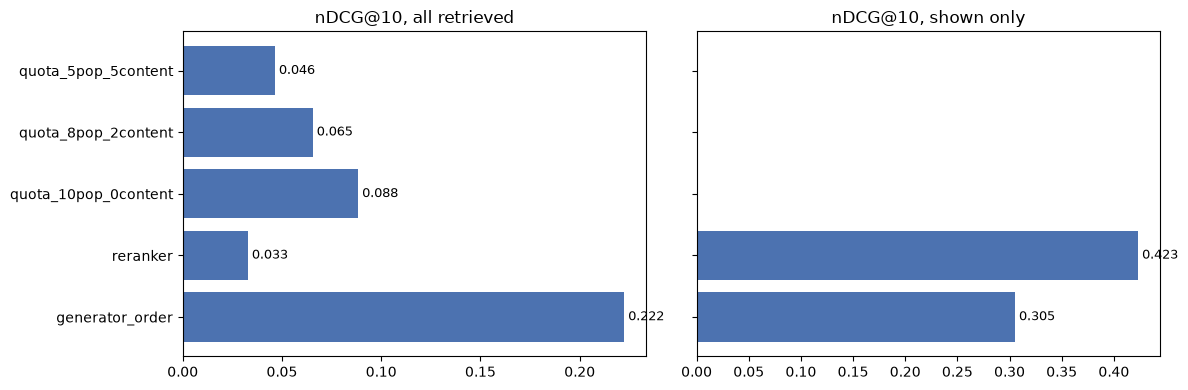

In [ ]:
shown = pipeline_results.filter(pl.col("scope") == "shown_only")
for metric in ("ndcg_at_10", "recall_at_10"):
    generator = shown.filter(pl.col("model") == "generator_order")[metric][0]
    reranker = shown.filter(pl.col("model") == "reranker")[metric][0]
    print(f"Shown-only {metric}: generator {generator:.4f} -> reranker {reranker:.4f} ({reranker / generator - 1:+.1%})")

top_k = scores.with_columns(
    pl.col("score").rank("ordinal", descending=True).over("impression_uid").alias("rank")
).filter(pl.col("rank") <= TOP_K)
shown_in_top = top_k.join(shown_scores.select("impression_uid", "news_code"), on=["impression_uid", "news_code"], how="semi")
print(f"Reranker top {TOP_K}: {1 - top_k['is_popularity'].mean():.1%} content candidates, "
      f"{shown_in_top.height / top_k.height:.1%} ever shown")

fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for axis, scope in zip(axes, ("all_retrieved", "shown_only")):
    table = pipeline_results.filter(pl.col("scope") == scope)
    axis.barh(table["model"].to_list(), table["ndcg_at_10"].to_list(), color="#4C72B0")
    for y, value in enumerate(table["ndcg_at_10"].to_list()):
        axis.text(value, y, f" {value:.3f}", va="center", fontsize=9)
    axis.set_title(f"nDCG@10, {scope.replace('_', ' ')}")
    axis.invert_yaxis()
plt.tight_layout()
plt.show()

# 6. Sample Recommendations

The final top 10 for one impression: the retriever that produced each article, whether it
was shown in the logged slate, and whether it was clicked (unknown if not shown).

In [ ]:
sample_uid = shown_scores.filter(pl.col("impression_uid").is_in(
    shown_pairs.filter(pl.col("clicked") == 1).select("impression_uid").collect()["impression_uid"].implode()
))["impression_uid"][0]

recommendations = (
    scores.filter(pl.col("impression_uid") == sample_uid)
    .sort(["score", "news_code"], descending=[True, False])
    .head(TOP_K)
    .join(shown_pairs.filter(pl.col("impression_uid") == sample_uid).collect(), on=["impression_uid", "news_code"], how="left")
    .select(
        pl.int_range(1, pl.len() + 1).alias("rank"),
        "news_code",
        pl.when(pl.col("is_popularity")).then(pl.lit("popularity")).otherwise(pl.lit("content")).alias("retriever"),
        pl.col("cutoff").alias("generator_rank"),
        "score",
        pl.col("clicked").is_not_null().alias("shown"),
        pl.col("clicked"),
    )
)
print(f"Impression {sample_uid}")
recommendations

Impression 10100549


rank,news_code,retriever,generator_rank,score,shown,clicked
i64,i64,str,i16,f32,bool,i8
1,25791,"""popularity""",204,0.005268,false,null
2,12589,"""content""",439,0.00444,false,null
3,14726,"""popularity""",149,0.003425,true,0
4,33885,"""popularity""",5,0.003178,true,0
5,54489,"""content""",402,0.003088,false,null
6,9349,"""popularity""",79,0.002797,false,null
7,39317,"""popularity""",6,0.002757,true,0
8,35906,"""popularity""",125,0.0026,false,null
9,16915,"""content""",322,0.002485,false,null


# 7. Interpretation

Results on 10,000 validation impressions (500 candidates each):

| Scope | Ordering | nDCG@10 | Recall@10 |
|---|---|---|---|
| All retrieved | Generator order | **0.222** | 0.357 |
| All retrieved | Quota 10 pop / 0 content | 0.088 | 0.168 |
| All retrieved | Quota 8 pop / 2 content | 0.066 | 0.142 |
| All retrieved | Reranker | 0.033 | 0.058 |
| Shown only | Generator order | 0.305 | 0.494 |
| Shown only | Reranker | **0.423** (+39%) | 0.627 (+27%) |

Candidate recall is 0.803: 80% of known clicks survive candidate generation, which caps
every ranking metric above.

- **Candidate generation does its job.** It cuts the ~104k-article catalogue to 500 per
  request while keeping 80% of known clicks reachable, so the reranker scores about 200×
  fewer articles.
- **The reranker ranks well wherever relevance is known.** On shown candidates it beats the
  generator order by 39% nDCG@10.
- **The all-retrieved metric is a lower bound.** Only about 5.6% of candidates were ever
  shown, and only a few hundred came from the content model. The reranker fills about 71%
  of its top 10 with content candidates, and those can never count as clicks offline, so
  any ordering that departs from the logging policy (mostly popular articles) is penalised.
  The quota merge shows it's not only the content candidates: with 10 popularity slots the
  reranker still promotes popular articles that were rarely shown.
- **Part of the gap is likely real train–serve shift.** The reranker was trained only on
  logged slates, which the logging policy had already filtered. Content candidates are
  selected for high similarity, which puts them at the extreme of the features the model
  trusts most, and never-exposed articles look like freshly published ones. Training with
  retrieved-but-unshown candidates as weak negatives, or calibrating scores per retriever,
  would address this.
- Whether promoting unshown content articles helps users can't be measured on logged MIND
  data; that needs online testing or counterfactual evaluation.